<a href="https://colab.research.google.com/github/SlastuninAE/python-practice-algos/blob/master/636-01/hw-8-slastunin-a-e.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kagglehub[pandas-datasets]

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report, precision_recall_curve, auc, f1_score

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import logging
logging.getLogger("kagglehub").setLevel(logging.ERROR)

# Задача 1.

In [4]:
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "mlg-ulb/creditcardfraud",
  "creditcard.csv",
)

print(df.shape)
print(df.head())
print(df.tail())

(284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

In [5]:
X = df.drop('Class', axis=1)
y = df['Class']
X[['Time', 'Amount']] = StandardScaler().fit_transform(X[['Time', 'Amount']])

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Задача 2.

In [32]:
X_train_normal = X_train[y_train == 0]
iso = IsolationForest(n_estimators=100, contamination=0.00172, random_state=42)
iso.fit(X_train_normal)
scores_iso = -iso.score_samples(X_test)
precision_iso, recall_iso, _ = precision_recall_curve(y_test, scores_iso)
pr_auc_iso = auc(recall_iso, precision_iso)
print(f"PR-AUC: {pr_auc_iso:.3f}")

f1_scores = []
for t in np.percentile(scores_iso, np.arange(80, 100, 0.5)):
    y_pred = (scores_iso > t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
best = np.percentile(scores_iso, 80 + 0.5 * np.argmax(f1_scores))
y_pred_best = (scores_iso > best).astype(int)

print(f"Лучший порог по F1: {best:.3f}")
print(classification_report(y_test, y_pred_best, target_names=['Норма', 'Мошенничество']))


PR-AUC: 0.168
Лучший порог по F1: 0.612
               precision    recall  f1-score   support

        Норма       1.00      1.00      1.00     56864
Мошенничество       0.16      0.46      0.23        98

     accuracy                           0.99     56962
    macro avg       0.58      0.73      0.62     56962
 weighted avg       1.00      0.99      1.00     56962



# Задача 3.

In [19]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.00172, novelty=True)
lof.fit(X_train)

scores_lof = -lof.score_samples(X_test)
precision, recall, _ = precision_recall_curve(y_test, scores_lof)
pr_auc = auc(recall, precision)
print(f"PR-AUC: {pr_auc:.3f}")

f1_scores = []
for t in np.percentile(scores_lof, np.arange(80, 100, 0.5)):
    y_pred = (scores_lof > t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
best = np.percentile(scores_lof, 80 + 0.5 * np.argmax(f1_scores))
y_pred_best = (scores_lof > best).astype(int)

print(f"Лучший порог по F1: {best:.3f}")
print(classification_report(y_test, y_pred_best, target_names=['Норма', 'Мошенничество']))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


PR-AUC: 0.003
Лучший порог по F1: 1.860
               precision    recall  f1-score   support

        Норма       1.00      0.99      0.99     56864
Мошенничество       0.01      0.08      0.02        98

     accuracy                           0.98     56962
    macro avg       0.50      0.53      0.50     56962
 weighted avg       1.00      0.98      0.99     56962



# Задача 4.

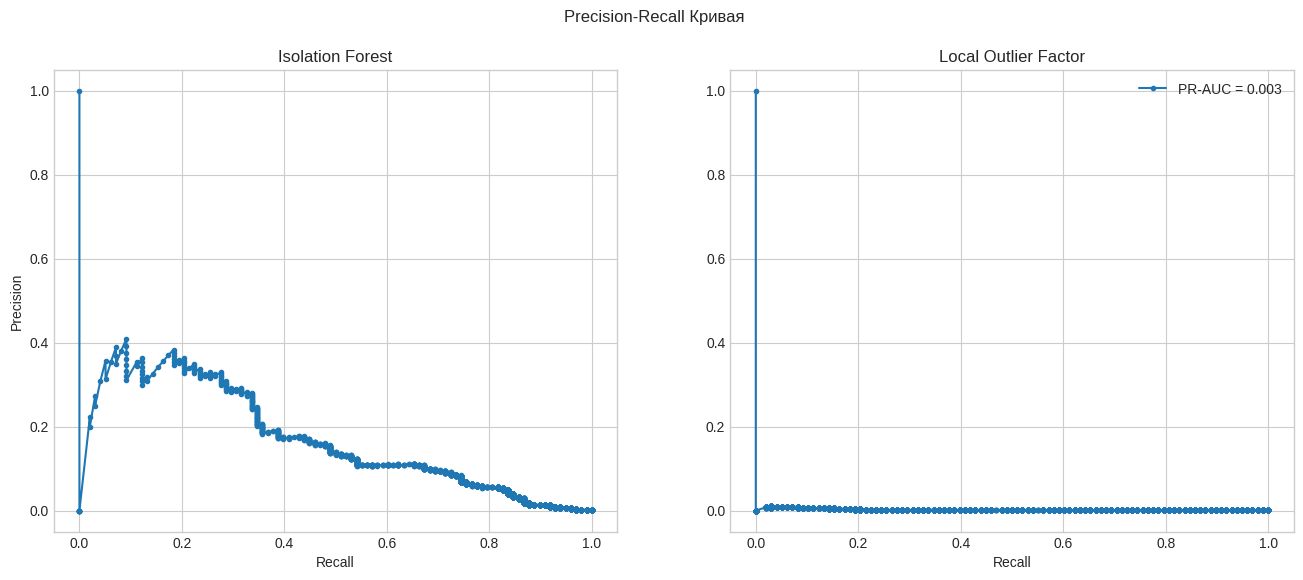

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(recall_iso, precision_iso, marker='.', label=f'PR-AUC = {pr_auc_iso:.3f}')
axes[0].set_title('Isolation Forest')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')

axes[1].plot(recall, precision, marker='.', label=f'PR-AUC = {pr_auc:.3f}')
axes[1].set_title('Local Outlier Factor')
axes[1].set_xlabel('Recall')

plt.suptitle('Precision-Recall Кривая')
plt.legend()
plt.grid(True)
plt.show()

# Задача 5.

1. Какая модель лучше нашла мошеннические транзакции?

### Isolation Forest

2. Почему ROC-AUC здесь может быть высоким (0.95+), но это будет обманчиво?

### Процент мошеннических транзакций слишком мал, из-за этого точность будет высокой, даже если за обычные транзакции примутся и мошеннические(В нашем датасете "Контекст: Это транзакции за 2 дня. Из 284 807 транзакций мошенническими являются всего 492 (0.172%) - классический пример экстремального дисбаланса.", если предположить, что мошеннических транзакций нет, то получится больше 99% верных предположений)

3. Как изменится Recall и Precision, если понизить contamination до 0.001 (0.1%)?

### Recall упадёт, так как contamination отвечает за ожидаемое количество аномалий, то при его уменьшении меньше транзакций будут засчитаны за мошеннические
### Precision увеличится, так как количество аномалий уменьшится, там останутся более вероятные мошеннические транзакции